In [ ]:
# 基础库
import numpy as np
import xarray as xr
import os
import sys
import gc  
import pickle

# 统计分析库
import statsmodels.api as sm
from scipy.stats import norm, ttest_1samp
import pymannkendall as mk
from scipy.stats import pearsonr
from scipy.stats import linregress
from scipy import stats


# 可视化库
from matplotlib import gridspec, pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.colors import LinearSegmentedColormap
import warnings
warnings.filterwarnings("ignore")

# 自定义模块
sys.path.append('/public/home/zhujw/work/guoly/code/Self-package/ccg_filter')
import ccg_filter

def mk_test(x):
    ## mk检验，输入时间序列W后，输出对应的标准正态值
    S = 0
    n = len(x)
    for i in range(n - 1):
        for j in range(i + 1, n):
            S += np.sign(x[j] - x[i])
    data_sort = np.sort(x)
    num = 0
    nn = 0
    for i in range(len(x) - 1):
        if data_sort[i + 1] - data_sort[i] <= 1.0e-37:
            nn += 1
        else:
            num += nn * (nn - 1) * (2 * nn + 5)
            nn = 1
    var_s = (n * (n - 1) * (2 * n + 5) - num) / 18
    if S > 0:
        Z = (S - 1) / np.sqrt(var_s)
    elif S == 0:
        Z = 0
    elif S < 0:
        Z = (S + 1) / np.sqrt(var_s)

    return Z

def trend_window(AMP, min_line, cal_type=None, mk_type=None):
#    这个函数用来计算AMP的滑动窗口趋势，或者非滑动窗口趋势
#    AMP 原始序列 min_line 滑动窗口最小数 
#    当cal_type不为空时，使用gls方法计算b
    b = []
    p = []
    x = np.arange(1, len(AMP) + 1)
    line_start = x[:len(x) - min_line + 1]
    for i in range(len(line_start)):
        AMP_now = AMP[i:i + min_line]
        x_now = np.arange(1, min_line + 1)

        if cal_type is not None:
            x_now = sm.add_constant(x_now)
            gls_model = sm.GLS(AMP_now, x_now)
            gls_results = gls_model.fit()
            params = gls_results.params
            b.append(params[1])
            if mk_type is not None:
                p.append(1 - norm.cdf(mk_test(AMP_now[~np.isnan(AMP_now)]), 0, 1))
            else:
                result = mk.original_test(AMP_now)
                p.append(result.p)
        
        else:
            b0 = np.polyfit(x_now[~np.isnan(AMP_now)], AMP_now[~np.isnan(AMP_now)], 1)  # min_square的系数
            if mk_type is not None:
                p.append(1 - norm.cdf(mk_test(AMP_now[~np.isnan(AMP_now)]), 0, 1))
            else:
                result = mk.original_test(AMP_now)
                p.append(result.p)
            b.append(b0[0])

    Z = np.vstack((p, b))
    return Z

def cal_trend_diff(data, time, min_len, trend_select, p_threshold=0.1, site=None, ratio_flag=None):
    """
    计算数据的heatmap和时间映射

    Parameters:
    data : 一维数组，原始数据
    time : 一维数组，时间序列
    min_len : int，最小窗口长度，用于计算趋势
    trend_select : int，选取计算趋势差的窗口长度
    ratio_flag : True/False，是否返回趋势差的比值形式

    Returns:
    diff : 一维数组，包含趋势差
    sign_start : int，趋势开始的符号
    """
    len_amp = len(data)

    # 初始化 heat_map 和 time_map ([p, b], start_time, end_time)
    heat_map = np.full((2, len_amp - min_len, len_amp - min_len), np.nan)
    time_map = np.full((2, len_amp - min_len, len_amp - min_len), np.nan)

    # 计算趋势的 heat_map 和时间映射
    for i in range(len_amp - min_len):
        for j in range(i + min_len, len_amp):
            # # 1) 只保留「前 trend_select 行」和「最后 trend_select 行」
            # if i > trend_select and i < (len_amp - trend_select - min_len):
            #     continue
            # # 2) 只保留「窗口长度 <= trend_select」的对角线附近区域
            # if (j - i - min_len) > trend_select:
            #     continue
            amp_now = data[i:j]
            trend_result = trend_window(amp_now, j - i, cal_type=0, mk_type=1).squeeze()
            heat_map[:, i, j - min_len] = trend_result
            time_map[:, i, j - min_len] = [time[i], time[j]]

    # 计算趋势差 diff
    trend_start = heat_map[1, :trend_select, :trend_select]
    trend_end = heat_map[1, -trend_select:, -trend_select:]
    diff = trend_end - trend_start
    diff = diff[~np.isnan(diff)]
    print(f"Trend start: {np.nanmean(trend_start):.3f} \u00B1 {np.nanstd(trend_start):.3f}, Trend end: {np.nanmean(trend_end):.3f} \u00B1 {np.nanstd(trend_end):.3f}")

    # 计算显著性
    t, p_diff = ttest_1samp(diff.flatten(), popmean=0, nan_policy='omit')
    diff_mean = np.nanmean(diff)
    t_stat, p_start = ttest_1samp(trend_start.flatten(), popmean=0, nan_policy='omit')
    start_mean = np.nanmean(trend_start)
    t_end, p_end = ttest_1samp(trend_end.flatten(), popmean=0, nan_policy='omit')
    end_mean = np.nanmean(trend_end)

    if (p_diff > p_threshold) or (diff_mean == 0):
        sign = -1
    else:
        if diff_mean >= 0:
            if start_mean >= 0 and end_mean > 0: sign = 1
            elif start_mean <= 0 and end_mean >= 0: sign = 2
            elif start_mean < 0 and end_mean <= 0: sign = 3
        elif diff_mean < 0:
            if start_mean > 0 and end_mean >= 0: sign = 4
            elif start_mean >= 0 and end_mean <= 0: sign = 5
            elif start_mean <= 0 and end_mean < 0: sign = 6

    if ratio_flag:
        ratio = trend_end / trend_start
        ratio = ratio[~np.isnan(ratio)]
        return diff, sign, p_diff, ratio, heat_map, time_map
    else:
        return diff, sign, p_diff, heat_map, time_map

def p_to_stars(p):
    if p <= 0.001:
        return '***'
    elif p <= 0.05:
        return '**'
    elif p <= 0.1:
        return '*'
    else:
        return ''

def quad_fit(time, amp, deg=2, ci_k=1.96):
    """
    deg: 多项式阶数，默认二次
    ci_k: 置信区间倍数，默认 1.96 95% 置信区间

    对 (time, amp) 做二次多项式拟合，返回：
      time_fit   : 拟合曲线用的时间（与 time 同单位）
      amp_fit    : 拟合曲线值
      amp_lower  : 置信区间下界（整体残差 std 方法）
      amp_upper  : 置信区间上界
      p_overall  : 整体回归 F 检验 p 值
      coeffs     : 多项式系数 np.polyfit 返回的 p
    """
    time = np.asarray(time, dtype=float)
    amp  = np.asarray(amp,  dtype=float)

    # 平移时间以减小共线性问题
    t0   = time.mean()
    t_rel = time - t0
    coeffs = np.polyfit(t_rel, amp, deg) 
    
    # 拟合曲线
    t_fit = np.linspace(t_rel.min(), t_rel.max(), 200)
    amp_fit = np.polyval(coeffs, t_fit)

    # 预测值与残差（在原始采样点上）
    amp_pred = np.polyval(coeffs, t_rel)
    residuals = amp - amp_pred

    # 残差标准差（整体噪声水平）
    sigma = residuals.std(ddof=1)

    # 简单置信区间（不区分 x 位置）：amp_fit ± k·sigma
    amp_upper = amp_fit + ci_k * sigma
    amp_lower = amp_fit - ci_k * sigma

    # ---------- 计算整体回归 p 值（F 检验） ----------
    n = len(amp)
    p_params = deg + 1              # 二次 = 3 个系数
    ss_tot = np.sum((amp - amp.mean())**2)
    ss_reg = np.sum((amp_pred - amp.mean())**2)
    ss_res = np.sum((amp - amp_pred)**2)

    dof_reg = p_params - 1
    dof_res = n - p_params
    r2 = ss_reg / ss_tot

    if dof_res > 0 and ss_res > 0:
        ms_reg = ss_reg / dof_reg
        ms_res = ss_res / dof_res
        F = ms_reg / ms_res
        p_overall = 1 - stats.f.cdf(F, dof_reg, dof_res)
    else:
        p_overall = np.nan

    # 把 t_fit 平移回原始时间
    time_fit = t_fit + t0

    return time_fit, amp_fit, amp_lower, amp_upper, p_overall, r2

In [2]:
site_folder = '/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/data/Fig-1-site+model/'
files = os.listdir(site_folder)
files.sort()

site_dict = {}
model_dict = {}
model_list = ['MBL', 'XCO2', 'CAMS-GC', 'Jena-GC', 'Trendy-GC']

for file in files:
    if not file.endswith('.nc'):
        continue
        
    site_name = file.split('.')[0]
    file_path = os.path.join(site_folder, file)
    
    with xr.open_dataset(file_path) as ds:
        time = ds['time'].values
        print(f"Processing {site_name} with time range {time[0]} to {time[-1]} and length {len(time)}\n")
        diff, sign, p_diff, ratio, trend_map, time_map = cal_trend_diff(ds['amp'].values, time, min_len=20, trend_select=8, site=site_name, ratio_flag=True)

        data_info = {
            'time': time,
            'amp': ds['amp_new'].values,
            'diff': diff,
            'sign': sign,
            'p_diff': p_diff,
            'ratio': ratio,
            'trend_map': trend_map,
            'time_map': time_map
        }
        
    # 根据名称分别存入站点或模型字典
    if site_name in model_list:
        model_dict[site_name] = data_info
    else:
        site_dict[site_name] = data_info

Processing ALT with time range 1985.0 to 2021.0 and length 37

Trend start: 0.079 ± 0.013, Trend end: 0.125 ± 0.009
Processing BRW with time range 1971.0 to 2021.0 and length 51

Trend start: 0.086 ± 0.024, Trend end: 0.123 ± 0.012
Processing CAMS-GC with time range 1981.0 to 2021.0 and length 41

Trend start: 0.075 ± 0.009, Trend end: 0.140 ± 0.014
Processing CBA with time range 1979.0 to 2021.0 and length 43

Trend start: 0.039 ± 0.014, Trend end: 0.010 ± 0.034
Processing FSD with time range 1990.0 to 2021.0 and length 32

Trend start: 0.112 ± 0.036, Trend end: 0.160 ± 0.013
Processing ICE with time range 1993.0 to 2021.0 and length 29

Trend start: 0.070 ± 0.025, Trend end: 0.086 ± 0.030
Processing Jena-GC with time range 1981.0 to 2021.0 and length 41

Trend start: 0.059 ± 0.011, Trend end: 0.082 ± 0.016
Processing MBL with time range 1979.0 to 2021.0 and length 43

Trend start: 0.029 ± 0.012, Trend end: 0.099 ± 0.012
Processing MHD with time range 1992.0 to 2021.0 and length 30

T

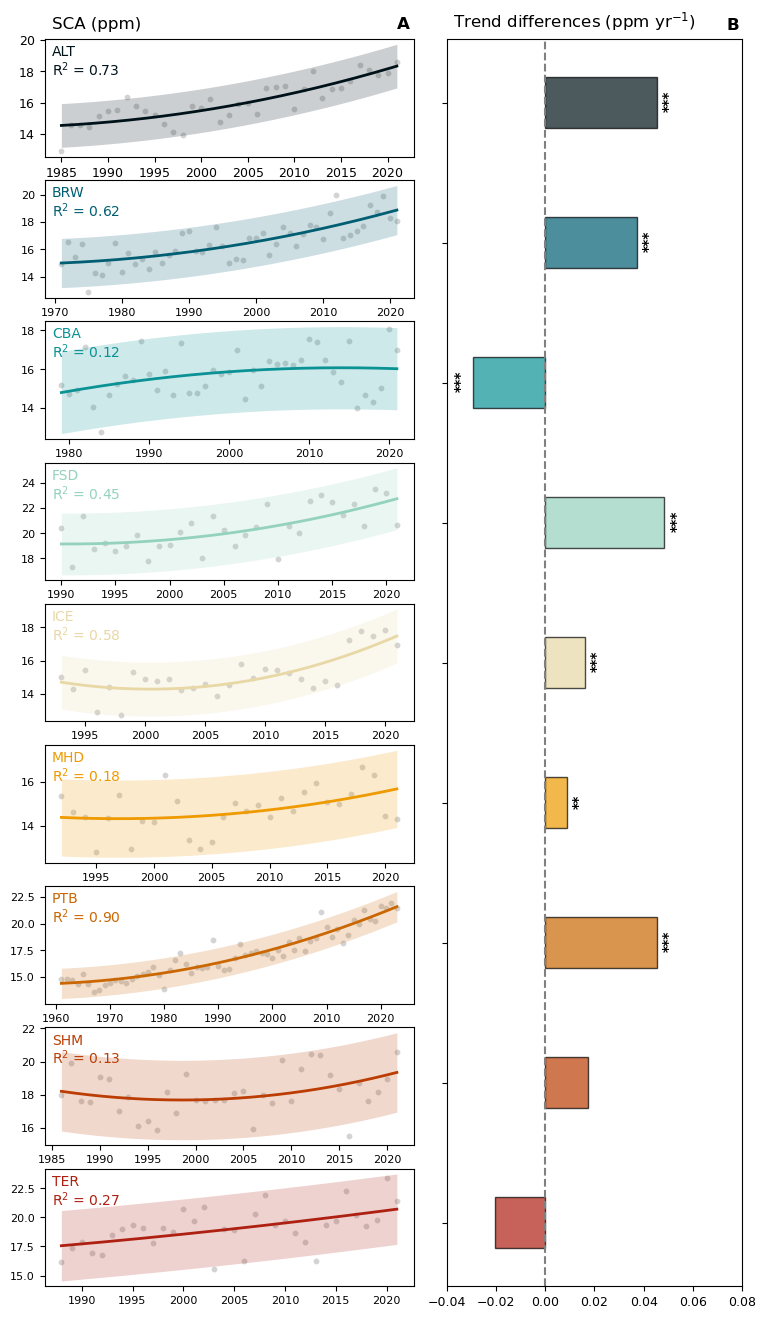

In [ ]:
# site
n_site = len(site_dict)
gs = gridspec.GridSpec(n_site, 2, wspace=0.1, hspace=0.2, height_ratios=[1]*n_site, width_ratios=[1, 0.8])
fig = plt.figure(figsize=(9, 1.8*n_site))
axs = np.empty((n_site), dtype=object)
for i, site in enumerate(site_dict):
    axs[i] = fig.add_subplot(gs[i, 0])
ax_bar = fig.add_subplot(gs[:, -1])
axs = np.append(axs, ax_bar)  

color_map = ['#001219', '#005f73', '#0a9396', '#94d2bd', '#e9d8a6',
             '#ee9b00', '#ca6702', '#bb3e03', '#ae2012', '#9b2226']

cm_custom = LinearSegmentedColormap.from_list('custom', color_map)
color_list = [cm_custom(i / n_site) for i in range(n_site)]


for i, (site, info) in enumerate(site_dict.items()):
    ax = axs[i]
    amp = info['amp']
    time = info['time']
    time_fit, amp_fit, amp_lower, amp_upper, p_overall, r2 = quad_fit(time, amp, deg=2, ci_k=1.96)

    ax.scatter(time, amp, color='lightgray', s=10, zorder=1)
    line_color = color_list[list(site_dict.keys()).index(site)]
    ax.plot(time_fit, amp_fit, color=line_color, label=site, linewidth=2, zorder=3)
    ax.fill_between(
        time_fit, amp_lower, amp_upper,
        color=line_color, alpha=0.2, linewidth=0, zorder=2
    )
    ax.text(
        0.02, 0.95, f'{site}',
        transform=ax.transAxes,
        fontsize=10,
        color=line_color,
        va='top',
        ha='left'
    )
    ax.text(
        0.02, 0.82,
        f'R$^{2}$ = {r2:.2f}',
        transform=ax.transAxes,
        fontsize=10,
        color=line_color,
        ha='left', 
        va='top'
    )
    ax.tick_params(axis='both', labelsize=8)

# region 3: bar plot in right panel (ax_bar)
ax = axs[-1]
sites = list(site_dict.keys()) 
site_diff = [np.mean(site_dict[site]['diff'][site_dict[site]['diff'] != 0]) for site in sites]
site_p    = [site_dict[site]['p_diff'] for site in sites]
ratio     = (np.array([np.mean(site_dict[site]['ratio'][site_dict[site]['ratio'] != 0]) for site in sites]) - 1) * 100
ratio_temp = [np.mean(site_dict[site]['ratio'][site_dict[site]['ratio'] != 0]) for site in sites]
bar_width = 0.4

hspace = 0.1
y_pos = np.array([i * (1 + hspace) + 0.5 for i in range(n_site)])
total_H = n_site * 1 + (n_site - 1) * hspace

# 柱状图使用所有颜色
ax.barh(
    y_pos, site_diff,
    edgecolor='black',
    alpha=0.7,
    height=bar_width,
    color=color_list
)


for i, (y, diff_val, p_val) in enumerate(zip(y_pos, site_diff, site_p)):
    star = p_to_stars(p_val)
    if diff_val >= 0:
        x_star = diff_val + 0.002
        ha = 'left'
    else:
        x_star = diff_val - 0.002
        ha = 'right'
    ax.text(
        x_star, y-0.01,
        star, rotation=90,
        ha=ha, va='center',
        fontsize=10, color='black', fontweight='bold'
    )

ax.set_yticks(y_pos)
# ax.set_yticklabels(sites, fontsize=10, rotation=0, ha='right', va='center')
ax.set_yticklabels([])
ax.axvline(x=0, color='gray', linestyle='--')
ax.set_xlim(-0.04, 0.08)
ax.set_ylim(total_H, 0)

letters = list('ABCDEFG')
target_axs = axs[[0, -1]]

titiles = ['SCA (ppm)', 'Trend differences (ppm yr$^{-1}$)']
for i, ax in enumerate(target_axs):
    # 根据子图的高度调整相对在 Y 轴顶部的偏移比例
    y_offset = 1.06 if ax == target_axs[0] else 1.005
    ax.text(0.99, y_offset, f'{letters[i]}', transform=ax.transAxes, 
            ha='right', va='bottom', fontsize=12, fontweight='bold')
    ax.text(0.02, y_offset, titiles[i], transform=ax.transAxes,
            ha='left', va='bottom', fontsize=12)

    ax.tick_params(axis='both', which='major', labelsize=9)

fig.savefig('/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/SI-fig/Part-1-site.png', dpi=500,
            bbox_inches='tight', pad_inches=0.1)

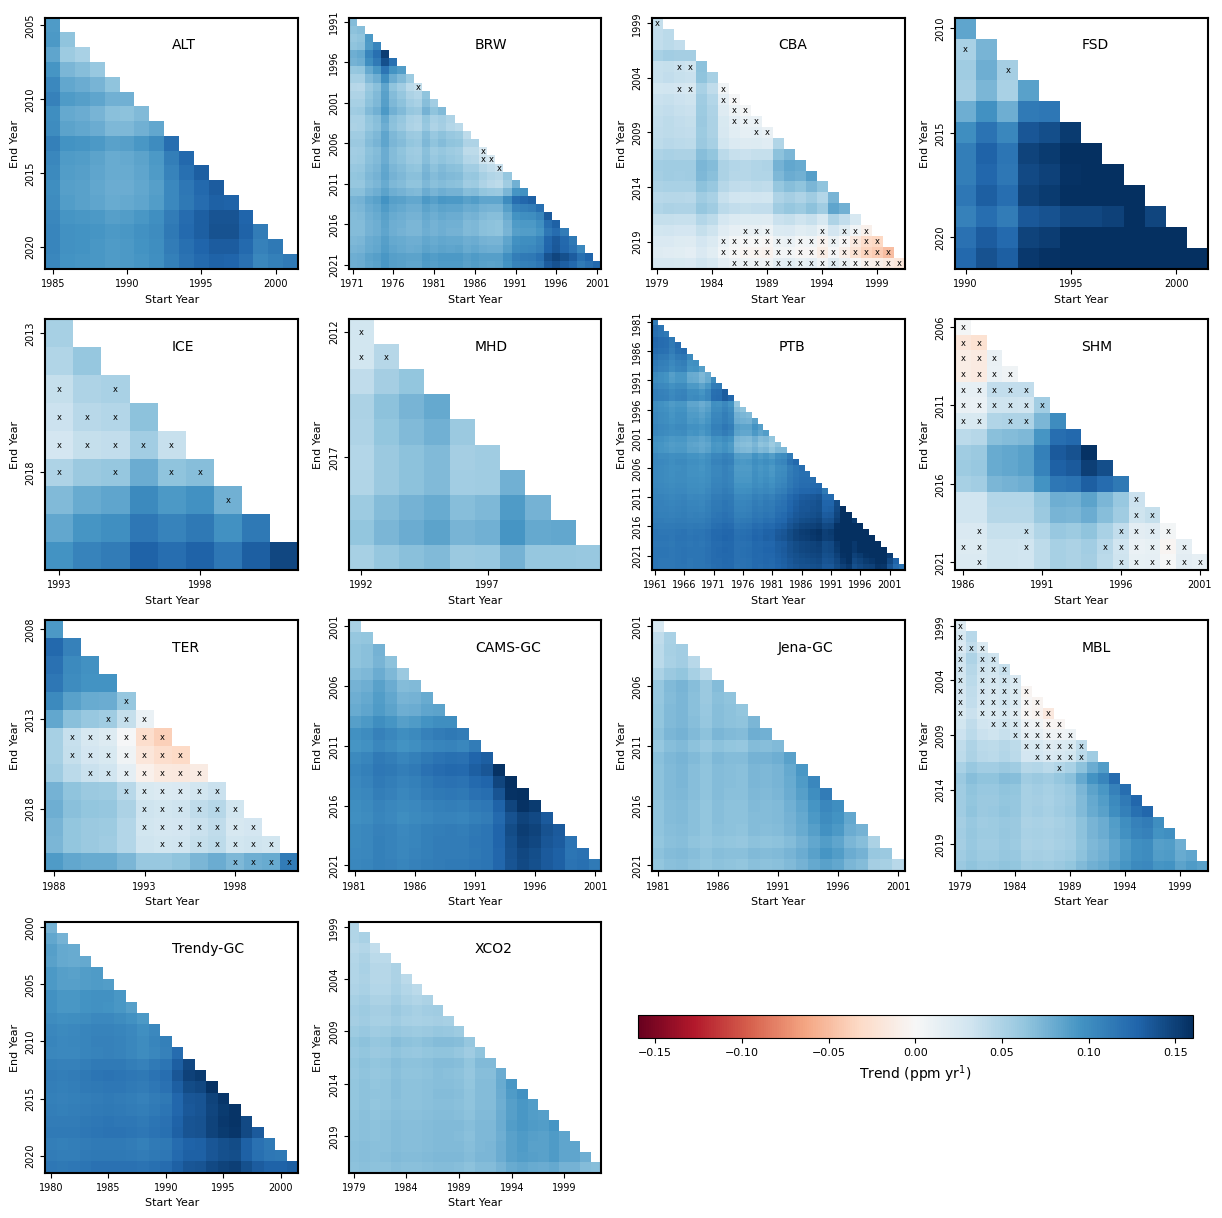

In [4]:
# trend matrix

gs = gridspec.GridSpec(4, 4, wspace=0.2, hspace=0.2, height_ratios=[1]*4, width_ratios=[1]*4)
fig = plt.figure(figsize=(15, 15))
axs = np.empty((4, 4), dtype=object)
for i in range(14):
    axs[i//4, i%4] = fig.add_subplot(gs[i//4, i%4])

combined_dict = {**site_dict, **model_dict}
for i, (site, info) in enumerate(combined_dict.items()):
    ax = axs[i//4, i%4]
    
    # 提取矩阵数据
    trend_map = info['trend_map'][1]
    p_map = info['trend_map'][0]
    time_map = info['time_map'] 
    time_max = np.nanmax(time_map)
    time_min = np.nanmin(time_map)

    x_tick = np.arange(time_min + 20, time_max + 1)          # End year
    y_tick = np.arange(time_min, time_max + 1 - 20)          # Start year


    # 旋转/翻转矩阵以匹配坐标展示
    flipped = np.flipud(np.rot90(trend_map, k=1))                   # 主值
    annot_raw = np.flipud(np.rot90(p_map, k=1))                 # 显著性辅助
    annot = np.where(annot_raw > 0.1, 'x', '')

    if site == 'PTB':  # 特殊站点坐标处理
        flipped = np.fliplr(np.flipud(flipped)).T
        annot = np.fliplr(np.flipud(annot)).T

    # 绘制 heatmap
    sns.heatmap(
        flipped,
        cmap='RdBu', 
        annot=annot,
        fmt='',
        cbar=False,
        ax=ax,
        annot_kws={'color': 'black', 'size': 6, 'ha': 'center', 'va': 'center'},
        vmin=-0.16,
        vmax=0.16
    )

    # 外边框
    for sp in ax.spines.values():
        sp.set_visible(True)
        sp.set_linewidth(1.5)

    # 每隔 5 年刻度 (根据数组长度安全获取)
    x_idx = np.arange(0, len(y_tick), 5)
    y_idx = np.arange(0, len(x_tick), 5)
    
    ax.set_xticks(x_idx + 0.5)
    ax.set_xticklabels(np.array(y_tick)[x_idx].astype(int), fontsize=7, rotation=0)
    
    ax.set_yticks(y_idx + 0.5)
    ax.set_yticklabels(np.array(x_tick)[y_idx].astype(int), fontsize=7, rotation=90)

    # 根据转置结果设置轴标签
    ax.set_xlabel('Start Year', fontsize=8)
    ax.set_ylabel('End Year', fontsize=8)

    # 标题与信息
    title_txt = f'{site}'
    ax.text(0.5, 0.92, title_txt, fontsize=10, transform=ax.transAxes,
            ha='left', va='top')

ax_cbar = fig.add_axes([0.52, 0.2, 0.37, 0.015])  # [left, bottom, width, height]
norm = plt.Normalize(vmin=-0.16, vmax=0.16)
sm = plt.cm.ScalarMappable(cmap='RdBu', norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, cax=ax_cbar, orientation='horizontal')
cbar.set_label('Trend (ppm yr$^{1}$)', fontsize=10)
cbar.ax.tick_params(labelsize=8)

fig.savefig('/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/SI-fig/Part-1-trend-map.png', dpi=500,
            bbox_inches='tight', pad_inches=0.1)

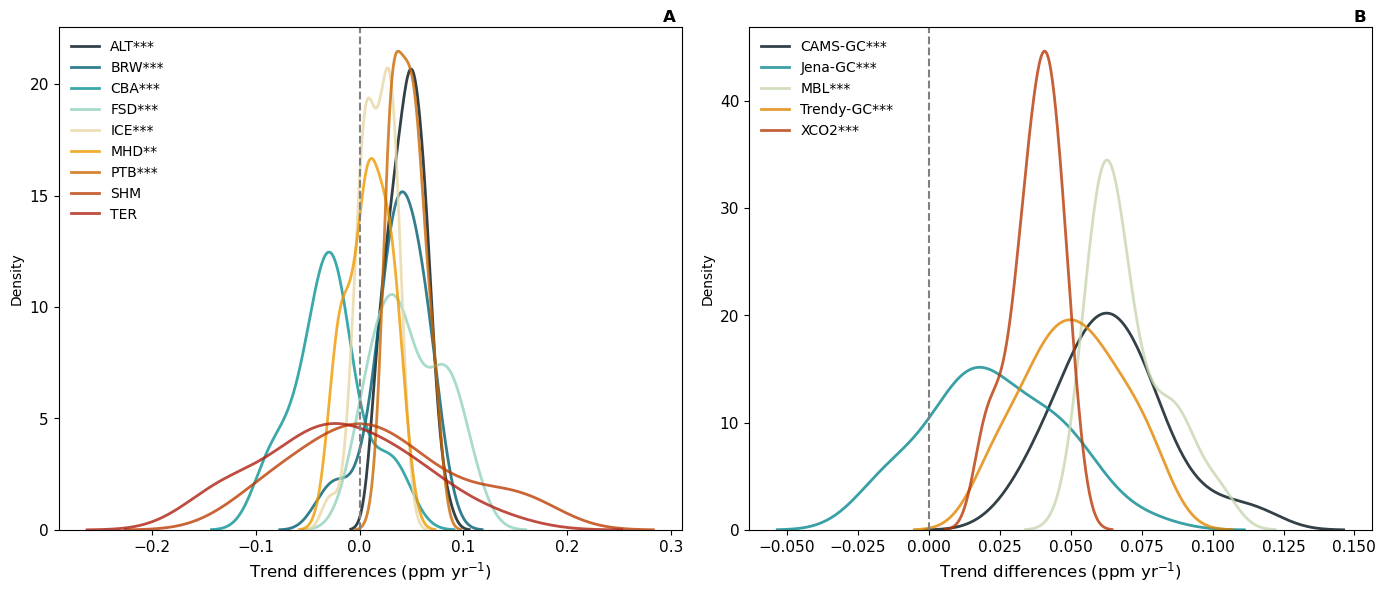

In [5]:
# PDF

fig, axs = plt.subplots(1, 2, figsize=(14, 6))

color_map = ['#001219', '#005f73', '#0a9396', '#94d2bd', '#e9d8a6',
             '#ee9b00', '#ca6702', '#bb3e03', '#ae2012', '#9b2226']
cm_custom = LinearSegmentedColormap.from_list('custom', color_map)

# 画左侧 Site
ax = axs[0]
n_site = len(site_dict)
color_list_site = [cm_custom(i / (n_site if n_site > 1 else 1)) for i in range(n_site)]

for i, (site, info) in enumerate(site_dict.items()):
    diff = info['diff']
    diff = diff[diff != 0]
    p_diff = info['p_diff']
    label = f"{site}{p_to_stars(p_diff)}"
    sns.kdeplot(diff, fill=False, label=label, color=color_list_site[i], alpha=0.8, ax=ax, linewidth=2)

# 画右侧 Model
ax = axs[1]
n_model = len(model_dict)
color_list_model = [cm_custom(i / (n_model if n_model > 1 else 1)) for i in range(n_model)]

for i, (model, info) in enumerate(model_dict.items()):
    diff = info['diff']
    diff = diff[diff != 0]
    p_diff = info['p_diff']
    label = f"{model}{p_to_stars(p_diff)}"
    sns.kdeplot(diff, fill=False, label=label, color=color_list_model[i], alpha=0.8, ax=ax, linewidth=2)

for ax in axs:
    ax.axvline(x=0, color='gray', linestyle='--')
    ax.legend(loc='upper left', fontsize=10, frameon=False)
    ax.text(0.5, -0.06, 'Trend differences (ppm yr$^{-1}$)', 
            transform=ax.transAxes, ha='center', va='top', fontsize=12)
    
letters = list('AB')
for i, ax in enumerate(axs.flat):
    ax.text(0.99, 1.02, f'{letters[i]}', transform=ax.transAxes, 
            ha='right', va='center', fontsize=12, fontweight='bold')
    ax.tick_params(axis='both', which='major', labelsize=11)
plt.tight_layout()

fig.savefig('/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/SI-fig/Part-1-pdf.png', dpi=500,
            bbox_inches='tight', pad_inches=0.1)